In [176]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features 


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [177]:
# Selection des données
catalogue = data.catalogue          # DataFrame indexé par nom lisible
charger = data.charger              # Fonction de chargement de données

# Sélection du dataset
selection = data.selectionner(sources=("12kDE","12kFE",),
                                  defauts=("IR", "B", "OR"),
                                  diametres=(7,),
                                  positions_or=("6",),
                                  charges=(0, 1, 2, 3),
                                  avec_sains=True)
# selection.groupby(["defaut", "diametre_mils"]).size().unstack(fill_value=0)

In [178]:
table = features.construire_table(selection, charger, canaux=("DE", "FE"))
# features.sauvegarder_table(table)                # écrit data/features/table_indicateurs.csv

INDICATEURS = indicateurs.COLONNES_TEMPORELS   # 4 indicateurs temporels (partie exploratoire)
# ORDRE = ["Sain", "IR007", "IR014", "IR021", "B007", "B014", "B021", "OR007", "OR014", "OR021"]
ORDRE = ["Sain", "IR007", "B007", "OR007"]


In [179]:
# table.iloc[70:100, :15]
table[table["canal"] == "FE"]

,fichier,fenetre,rpm,canal,numero,source,fs,defaut,position_OR,diametre_mils,...,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF,f_pic,classe
101,Normal_L0,0,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001018,0.006267,0.005233,0.006086,0.203094,0.285649,0.133188,0.378069,60.058594,Sain
102,Normal_L0,1,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001319,0.004294,0.006015,0.006202,0.154014,0.332968,0.194814,0.318204,60.791016,Sain
103,Normal_L0,2,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000574,0.007760,0.007006,0.005637,0.067372,0.160511,0.171577,0.600541,60.058594,Sain
104,Normal_L0,3,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000867,0.003905,0.011645,0.013029,0.251415,0.253171,0.209546,0.285868,30.761719,Sain
105,Normal_L0,4,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000781,0.008527,0.009871,0.011672,0.199272,0.142502,0.173827,0.484400,31.494141,Sain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3815,12kFE_OR007at6_L3,45,1733.0,FE,297,12kFE,12000,OR,6,7,...,0.015259,0.028909,0.257123,0.328492,0.259333,0.372349,0.319666,0.048653,29.296875,OR007
3816,12kFE_OR007at6_L3,46,1733.0,FE,297,12kFE,12000,OR,6,7,...,0.043822,0.049426,0.226794,0.276070,0.309198,0.364322,0.244797,0.081683,29.296875,OR007
3817,12kFE_OR007at6_L3,47,1733.0,FE,297,12kFE,12000,OR,6,7,...,0.015378,0.039207,0.129523,0.127879,0.184584,0.437060,0.270429,0.107927,88.623047,OR007
3818,12kFE_OR007at6_L3,48,1733.0,FE,297,12kFE,12000,OR,6,7,...,0.026528,0.033828,0.204134,0.269287,0.272817,0.344586,0.317211,0.065386,29.296875,OR007


In [180]:
table.groupby(["classe", "canal"]).size().unstack()


canal,DE,FE
classe,,
B007,401,401
IR007,401,401
OR007,402,402
Sain,706,706


In [181]:
#| label: preparation-modeling
#| code-summary: "Split par fichier + standardisation"
#| tbl-cap: "Répartition des fichiers entre apprentissage et test."

COLONNES_INDICATEURS = indicateurs.COLONNES_INDICATEURS
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling(table, COLONNES_INDICATEURS)
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="DE", canal_test="FE")

pd.DataFrame({
    "split": ["train", "test"],
    "fichiers": [g_train.nunique(), g_test.nunique()],
    "fenêtres": [len(X_train), len(X_test)],
    "classes présentes": [", ".join(sorted(y_train.unique())),
                          ", ".join(sorted(y_test.unique()))],
})

,split,fichiers,fenêtres,classes présentes
0,train,16,1310,"B007, IR007, OR007, Sain"
1,test,16,1306,"B007, IR007, OR007, Sain"


In [182]:
#| label: regression logistique
from sklearn import linear_model

logreg = linear_model.LogisticRegression(max_iter=500, random_state=24)
logregb = linear_model.LogisticRegression(max_iter=500, random_state=24, class_weight="balanced") ##  >> Pour gérer le déséquilibre de classes

logreg.fit(X_train, y_train)
logregb.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_predb = logregb.predict(X_test)
cm = pd.crosstab(y_test, y_pred, rownames=['Classe réelle'], colnames=['Classe prédite'])
cmb = pd.crosstab(y_test, y_predb, rownames=['Classe réelle'], colnames=['Classe prédite'])

In [ ]:
#| label: regression logistique pour avoir une base, avec comparaison class_weight="balanced" ou non
from sklearn.metrics import classification_report
print("###### LogReg standard ######")
display(cm)
print(classification_report(y_test, y_pred))

print("###### LogReg class_weight=balanced ######")
display(cmb)
print(classification_report(y_test, y_predb))

###### LogReg standard ######


Classe prédite,B007,IR007,OR007,Sain
Classe réelle,,,,
B007,82,10,4,104
IR007,112,86,2,0
OR007,0,0,200,0
Sain,0,0,0,706


              precision    recall  f1-score   support

        B007       0.42      0.41      0.42       200
       IR007       0.90      0.43      0.58       200
       OR007       0.97      1.00      0.99       200
        Sain       0.87      1.00      0.93       706

    accuracy                           0.82      1306
   macro avg       0.79      0.71      0.73      1306
weighted avg       0.82      0.82      0.81      1306

###### LogReg class_weight=balanced ######


Classe prédite,B007,IR007,OR007,Sain
Classe réelle,,,,
B007,99,9,4,88
IR007,103,96,1,0
OR007,0,1,199,0
Sain,0,0,0,706


              precision    recall  f1-score   support

        B007       0.49      0.49      0.49       200
       IR007       0.91      0.48      0.63       200
       OR007       0.98      0.99      0.99       200
        Sain       0.89      1.00      0.94       706

    accuracy                           0.84      1306
   macro avg       0.82      0.74      0.76      1306
weighted avg       0.84      0.84      0.83      1306



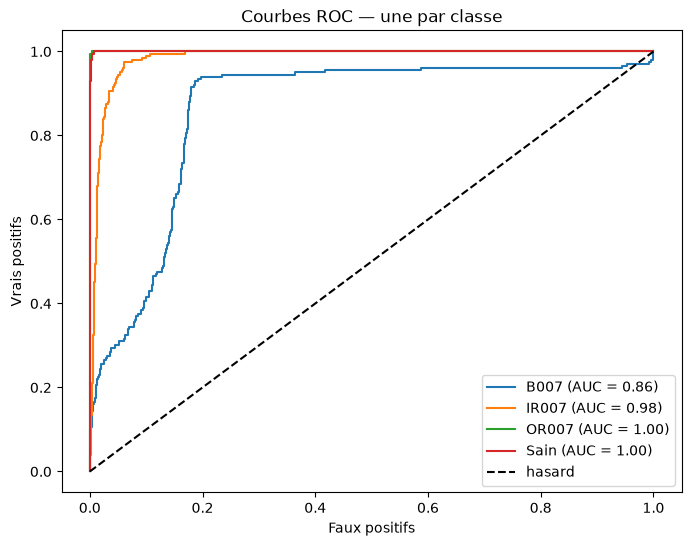

In [184]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Probabilités prédites (une colonne par classe)
probs = logreg.predict_proba(X_test)

# Vraies classes en 0/1 (une colonne par classe)
classes = logreg.classes_
y_bin = label_binarize(y_test, classes=classes)

# Courbes ROC par classe
plt.figure(figsize=(8, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("Faux positifs")
plt.ylabel("Vrais positifs")
plt.title("Courbes ROC — une par classe")
plt.legend()
plt.show()

In [189]:
#| label: arbre de décision : def+fit
from sklearn.tree import DecisionTreeClassifier

Model_tree = DecisionTreeClassifier(criterion='entropy', max_depth=8, random_state=123)
Model_tree.fit(X_train, y_train)
y_pred = Model_tree.predict(X_test)

In [190]:
#| label: arbre de décision : results
display(pd.crosstab(y_test, y_pred, rownames=['real'], colnames=['pred']))

print(classification_report(y_test, y_pred))

feats = {}
for feature, importance in zip(X_test.columns, Model_tree.feature_importances_):
    feats[feature] = importance
importances = pd.DataFrame.from_dict(feats, orient='index')
importances = importances.rename(columns={0:'Importance'})
importances = importances.sort_values('Importance', ascending=False)
display(importances[importances['Importance'] != 0])
display(importances[importances['Importance'] == 0])

pred,B007,IR007,OR007,Sain
real,,,,
B007,142,44,4,10
IR007,2,86,109,3
OR007,0,0,200,0
Sain,0,0,0,706


              precision    recall  f1-score   support

        B007       0.99      0.71      0.83       200
       IR007       0.66      0.43      0.52       200
       OR007       0.64      1.00      0.78       200
        Sain       0.98      1.00      0.99       706

    accuracy                           0.87      1306
   macro avg       0.82      0.78      0.78      1306
weighted avg       0.88      0.87      0.86      1306



,Importance
amp_BSF_3,0.576705
amp_FTF_3,0.245543
Kurtosis,0.177752


,Importance
RMS,0.0
Pic,0.0
amp_BPFI_1,0.0
Crete,0.0
amp_BPFO_1,0.0
amp_BPFI_2,0.0
amp_BPFO_2,0.0
amp_BPFO_3,0.0
amp_BSF_1,0.0
amp_BPFI_3,0.0


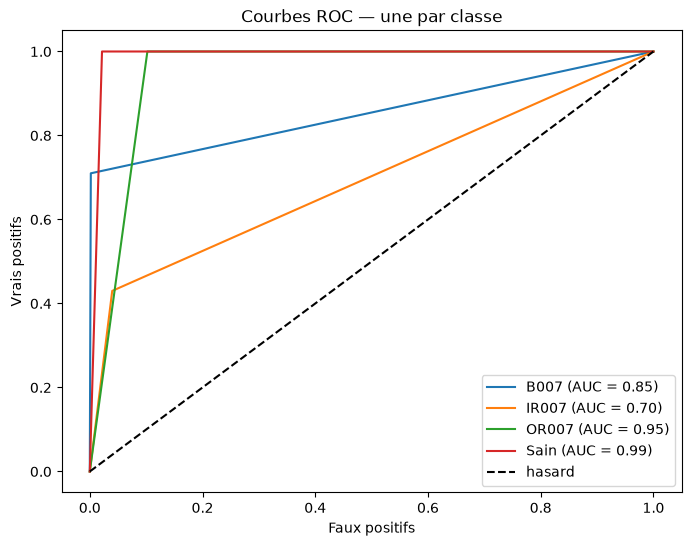

In [191]:
# Probabilités prédites (une colonne par classe)
probs = Model_tree.predict_proba(X_test)

# Vraies classes en 0/1 (une colonne par classe)
classes = Model_tree.classes_
y_bin = label_binarize(y_test, classes=classes)

# Courbes ROC par classe
plt.figure(figsize=(8, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("Faux positifs")
plt.ylabel("Vrais positifs")
plt.title("Courbes ROC — une par classe")
plt.legend()
plt.show()